<a href="https://colab.research.google.com/github/GAEL328530/Lab-pdi-PR-CTICAS/blob/main/Practica8_Filtros_Imagenes_Medicas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 8: Aplicación de Filtros en Imágenes Médicas

**Universidad Autónoma de Nuevo León · Facultad de Ingeniería Mecánica y Eléctrica · Semestre Enero-Junio 2026**

| Integrante | Matrícula |
|---|---|
| *Alexa Rodríguez Méndez* | *2133921* |
| *Gael Alejandro Reyes Zaragoza* | *2178099* |
| *René Alejandro Rodríguez Castañeda* | *2019068* |

**Brigada:** *309* · **Hora:** *N5*

---

## ¿Qué se hace en este notebook?

Se aplican filtros espaciales y filtros en el dominio de la frecuencia sobre imágenes médicas usando **Python, OpenCV, NumPy y Matplotlib**.

* **Parte I – Máscaras espaciales (radiografía de tórax):** filtros de suavizado (media, gaussiano y mediana con kernels de 3×3, 5×5 y 11×11), detección de bordes (Sobel en x e y, Laplaciano y Kirsch, incluyendo versiones modificadas a mano) y una máscara personalizada de realce y otra de detección.
* **Parte II – Dominio de la frecuencia (retinografía y tomografía de pulmón):** Transformada de Fourier, filtros pasa bajas (ideal y gaussiano con radios de 20, 50 y 80 px) y filtros pasa altas (círculo, anillo y cruz), mostrando la máscara, el espectro filtrado y la imagen reconstruida.

## 0. Configuración inicial

Se importan las librerías y se definen funciones auxiliares que se usarán en todo el notebook:

* `descargar`: baja una imagen desde internet si todavía no está en el entorno de Colab.
* `a_uint8`: lleva cualquier resultado (por ejemplo, un gradiente con valores negativos) al rango 0–255 para poder visualizarlo; usa un percentil como máximo para que unos cuantos píxeles muy brillantes no oscurezcan el resto.
* `mostrar`: dibuja una cuadrícula de imágenes con su título.

In [ ]:
import os
import urllib.request

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import data as skdata   # solo se usa para cargar la retinografía de ejemplo

plt.rcParams["figure.dpi"] = 100

URL_RX = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/right-upper-lobe-pneumonia-9-PA.jpg"
URL_TC = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/jkms-35-e79-g001-l-d.jpg"


def descargar(url, nombre):
    """Descarga el archivo solo si no existe todavía."""
    if not os.path.exists(nombre):
        peticion = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(peticion) as r, open(nombre, "wb") as f:
            f.write(r.read())


def a_uint8(img, percentil=99.5):
    """Lleva |img| al rango 0-255 para visualizarlo. Se usa un percentil como máximo para que
    unos cuantos píxeles muy brillantes (letras, marcos) no oscurezcan el resto de la imagen."""
    v = np.abs(img).astype(np.float32)
    tope = np.percentile(v, percentil)
    return np.clip(v / max(tope, 1e-6) * 255, 0, 255).astype(np.uint8)


def mostrar(imagenes, titulos, filas, columnas, tam=(4, 4)):
    """Muestra una cuadrícula de imágenes en escala de grises."""
    fig, axs = plt.subplots(filas, columnas, figsize=(columnas * tam[0], filas * tam[1]))
    axs = np.atleast_1d(axs).ravel()
    for ax, im, t in zip(axs, imagenes, titulos):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axs[len(imagenes):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# PARTE I · Filtros con máscaras espaciales personalizadas

## 1.1 Carga de la radiografía en escala de grises

Se descarga una radiografía PA de tórax y se lee directamente en escala de grises (`cv2.IMREAD_GRAYSCALE`). La imagen original es muy grande (más de 3000 px), por lo que se reduce a 1024 px de ancho con `INTER_AREA` para que los filtros se ejecuten rápido y los resultados se aprecien en pantalla.

Tamaño de la radiografía: (1104, 1024) | tipo: uint8


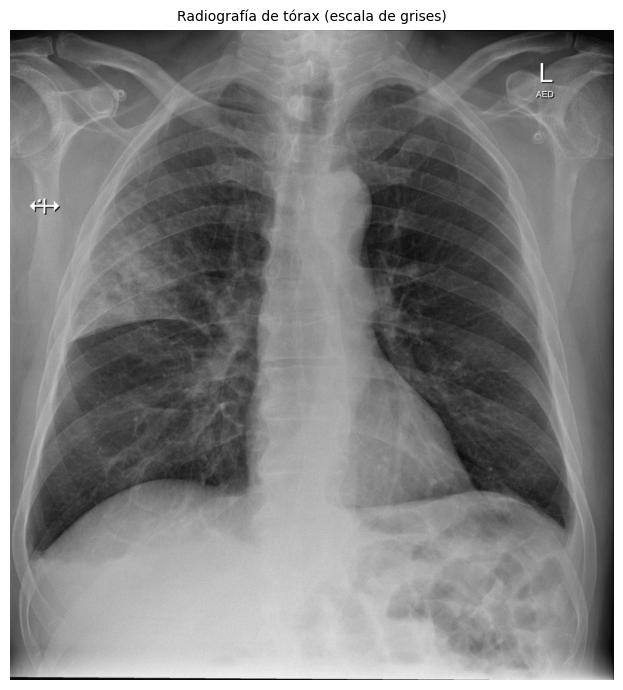

In [ ]:
descargar(URL_RX, "radiografia_torax.jpg")

rx = cv2.imread("radiografia_torax.jpg", cv2.IMREAD_GRAYSCALE)
escala = 1024 / rx.shape[1]
rx = cv2.resize(rx, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)

print("Tamaño de la radiografía:", rx.shape, "| tipo:", rx.dtype)
mostrar([rx], ["Radiografía de tórax (escala de grises)"], 1, 1, tam=(7, 7))

## 1.2 Filtros de suavizado (media, gaussiano y mediana)

Se aplican tres filtros pasa bajas con kernels de **3×3, 5×5 y 11×11**:

* **Media:** promedio simple de la vecindad (kernel de unos dividido entre k², aplicado con `cv2.filter2D`).
* **Gaussiano:** promedio ponderado, los píxeles cercanos al centro pesan más (`cv2.GaussianBlur`).
* **Mediana:** sustituye el píxel por la mediana de su vecindad (`cv2.medianBlur`); es un filtro no lineal.

Primero se muestra la imagen completa y después un acercamiento (ROI) a una zona del pulmón derecho, donde las diferencias se notan mucho mejor.

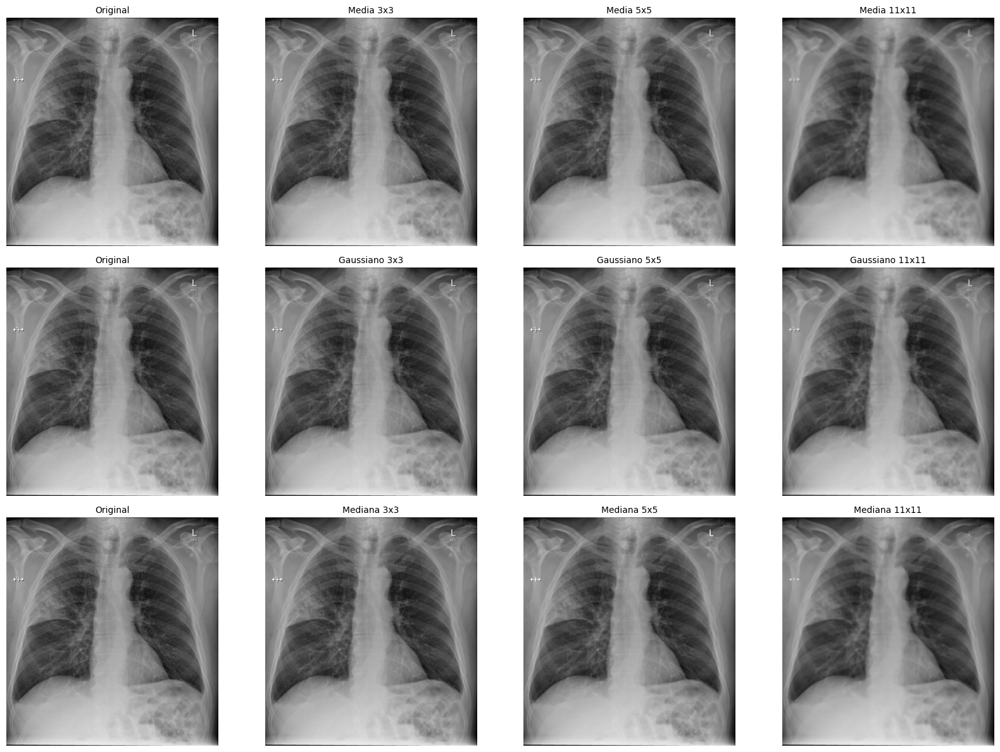

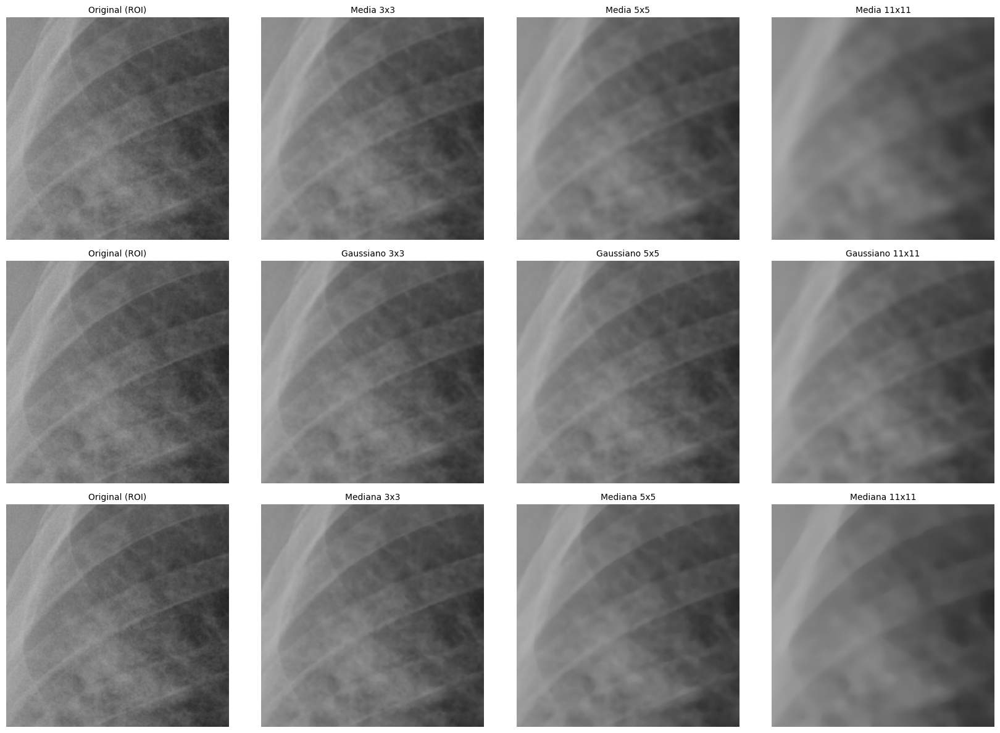

In [ ]:
tamanos = [3, 5, 11]

def filtro_media(img, k):
    kernel = np.ones((k, k), np.float32) / (k * k)      # máscara de promedio
    return cv2.filter2D(img, -1, kernel)

def filtro_gauss(img, k):
    return cv2.GaussianBlur(img, (k, k), 0)              # sigma calculado a partir de k

def filtro_mediana(img, k):
    return cv2.medianBlur(img, k)

filtros_suavizado = {"Media": filtro_media, "Gaussiano": filtro_gauss, "Mediana": filtro_mediana}

# Imagen completa: una fila por filtro, una columna por tamaño de kernel
imgs, tits = [], []
for nombre, f in filtros_suavizado.items():
    imgs.append(rx); tits.append("Original")
    for k in tamanos:
        imgs.append(f(rx, k)); tits.append(f"{nombre} {k}x{k}")
mostrar(imgs, tits, 3, 4, tam=(4.2, 4))

# Acercamiento a una región de interés (ROI) del pulmón derecho
y0, y1, x0, x1 = 260, 460, 120, 320
imgs, tits = [], []
for nombre, f in filtros_suavizado.items():
    imgs.append(rx[y0:y1, x0:x1]); tits.append("Original (ROI)")
    for k in tamanos:
        imgs.append(f(rx, k)[y0:y1, x0:x1]); tits.append(f"{nombre} {k}x{k}")
mostrar(imgs, tits, 3, 4, tam=(4.2, 4))

### Elección del tamaño del kernel (medición objetivo)

Para justificar el tamaño del kernel no basta con mirar las imágenes, así que se mide:

1. Se le agrega **ruido gaussiano sintético** a la radiografía (σ = 15) y se filtra. Con `cv2.PSNR` se compara contra la imagen limpia: a mayor PSNR, mejor se eliminó el ruido.
2. Se filtra la imagen limpia y se calcula la **varianza del Laplaciano**, una medida estándar de nitidez: a mayor valor, más detalle y bordes se conservan.

El mejor tamaño es el que logra buena reducción de ruido sin destruir el detalle.

In [ ]:
rng = np.random.default_rng(0)
ruido = rng.normal(0, 15, rx.shape)
rx_ruidosa = np.clip(rx.astype(np.float64) + ruido, 0, 255).astype(np.uint8)

def nitidez(img):
    """Varianza del Laplaciano: mide cuánto detalle/borde queda en la imagen."""
    return cv2.Laplacian(img, cv2.CV_64F).var()

filas = [{"Filtro": "Sin filtrar", "Kernel": "-",
          "PSNR (dB)": cv2.PSNR(rx, rx_ruidosa), "Nitidez": nitidez(rx)}]
for nombre, f in filtros_suavizado.items():
    for k in tamanos:
        filas.append({"Filtro": nombre, "Kernel": f"{k}x{k}",
                      "PSNR (dB)": cv2.PSNR(rx, f(rx_ruidosa, k)),
                      "Nitidez": nitidez(f(rx, k))})

tabla_suavizado = pd.DataFrame(filas)
print(tabla_suavizado.round(2).to_string(index=False))

     Filtro Kernel  PSNR (dB)  Nitidez
Sin filtrar      -      24.62   177.84
      Media    3x3      32.12    16.66
      Media    5x5      32.28     6.19
      Media  11x11      29.92     2.22
  Gaussiano    3x3      32.02    21.90
  Gaussiano    5x5      33.07    10.25
  Gaussiano  11x11      32.34     2.79
    Mediana    3x3      31.51    88.34
    Mediana    5x5      33.37    69.30
    Mediana  11x11      32.91    56.80


## 1.3 Filtros de detección de bordes: Sobel, Laplaciano y Kirsch

Se definen las máscaras a mano como arreglos de NumPy y se aplican con `cv2.filter2D` usando profundidad de 32 bits con signo (`cv2.CV_32F`), para no perder los valores negativos del gradiente.

* **Sobel x / Sobel y:** derivadas horizontal y vertical; la magnitud es √(Gx² + Gy²).
* **Laplaciano:** segunda derivada; resalta bordes en todas direcciones.
* **Kirsch:** ocho máscaras direccionales (N, NE, E, SE, S, SO, O, NO) obtenidas rotando los coeficientes 5 y −3; el resultado es el máximo de las ocho respuestas.

Máscara de Kirsch (dirección N):
 [[ 5.  5.  5.]
 [-3.  0. -3.]
 [-3. -3. -3.]]


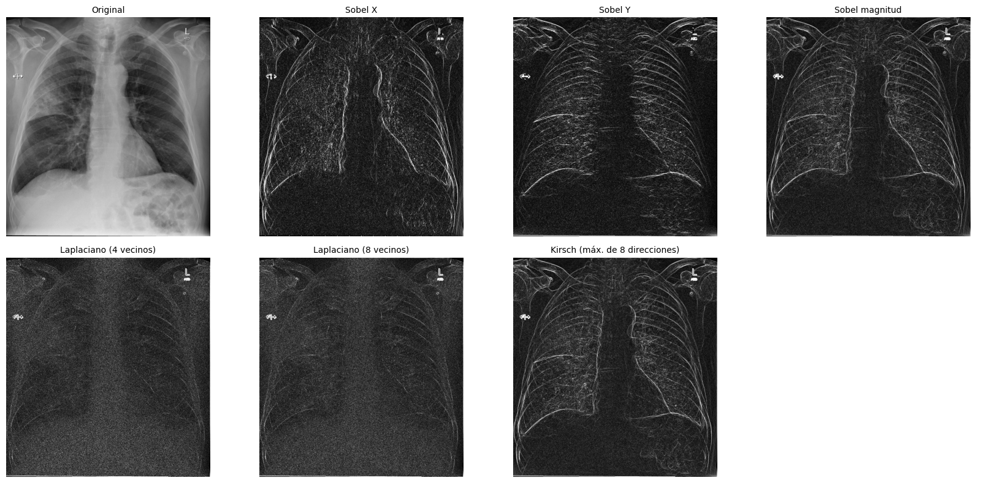

In [ ]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], np.float32)
sobel_y = sobel_x.T

laplaciano_4 = np.array([[0,  1, 0],
                         [1, -4, 1],
                         [0,  1, 0]], np.float32)
laplaciano_8 = np.array([[1,  1, 1],
                         [1, -8, 1],
                         [1,  1, 1]], np.float32)

def mascaras_kirsch():
    """Genera las 8 máscaras de Kirsch rotando la corona exterior de la máscara base."""
    posiciones = [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1), (2, 0), (1, 0)]
    base = [5, 5, 5, -3, -3, -3, -3, -3]
    mascaras = []
    for giro in range(8):
        m = np.zeros((3, 3), np.float32)
        for i, (r, c) in enumerate(posiciones):
            m[r, c] = base[(i - giro) % 8]
        mascaras.append(m)
    return mascaras

kirsch = mascaras_kirsch()
nombres_kirsch = ["N", "NE", "E", "SE", "S", "SO", "O", "NO"]
print("Máscara de Kirsch (dirección N):\n", kirsch[0])

def aplicar(img, mascara):
    return cv2.filter2D(img, cv2.CV_32F, mascara)

gx = aplicar(rx, sobel_x)
gy = aplicar(rx, sobel_y)
sobel_mag = np.sqrt(gx ** 2 + gy ** 2)
lap4 = aplicar(rx, laplaciano_4)
lap8 = aplicar(rx, laplaciano_8)
resp_kirsch = [aplicar(rx, m) for m in kirsch]
kirsch_max = np.max(np.stack(resp_kirsch), axis=0).clip(0)

mostrar([rx, a_uint8(gx), a_uint8(gy), a_uint8(sobel_mag),
         a_uint8(lap4), a_uint8(lap8), a_uint8(kirsch_max)],
        ["Original", "Sobel X", "Sobel Y", "Sobel magnitud",
         "Laplaciano (4 vecinos)", "Laplaciano (8 vecinos)", "Kirsch (máx. de 8 direcciones)"],
        2, 4, tam=(4.2, 4))

### Modificación manual de las máscaras

Para observar cómo cambia el resultado al alterar los coeficientes se prueban variantes:

* **Sobel X:** (a) estándar, (b) con más peso en la fila central (1-4-1), (c) Prewitt (pesos iguales 1-1-1) y (d) Sobel de 5×5.
* **Laplaciano:** (a) 4 vecinos, (b) 8 vecinos y (c) una versión modificada con coeficientes −1, 2, −1 que da más peso a los vecinos de las cruces.
* **Kirsch:** se muestran cuatro de las direcciones individuales y se comparan contra el máximo de las ocho.

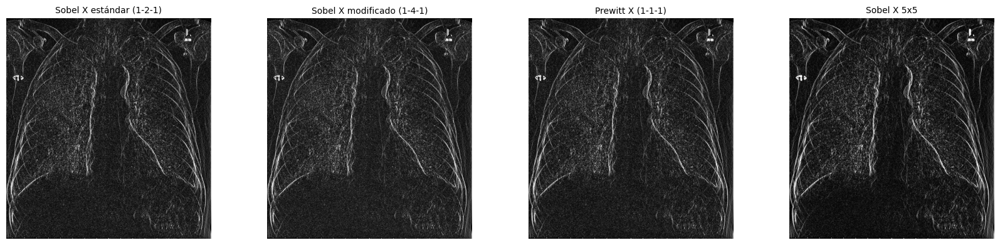

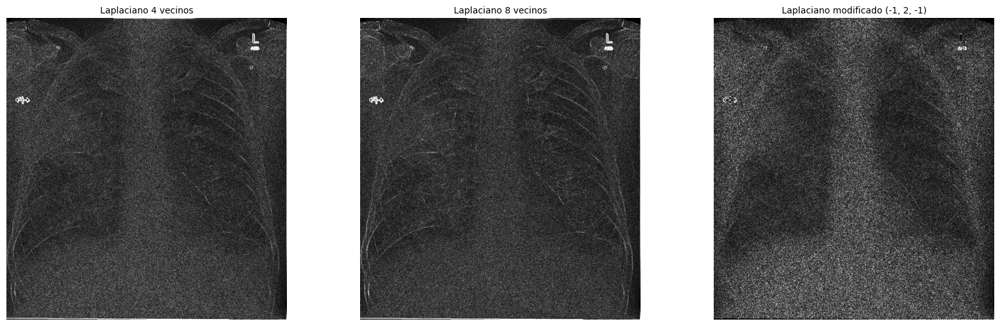

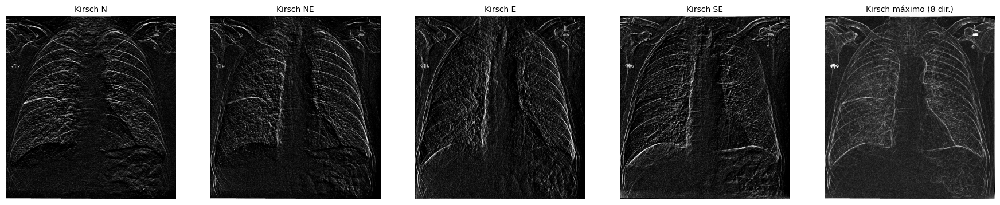

In [ ]:
# --- Variantes de Sobel X ---
sobel_x_fuerte = np.array([[-1, 0, 1],
                           [-4, 0, 4],
                           [-1, 0, 1]], np.float32)       # más peso al centro
prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]], np.float32)            # pesos iguales
sobel_x_5 = np.array([[-1,  -2, 0,  2, 1],
                      [-4,  -8, 0,  8, 4],
                      [-6, -12, 0, 12, 6],
                      [-4,  -8, 0,  8, 4],
                      [-1,  -2, 0,  2, 1]], np.float32)   # máscara 5x5

mostrar([a_uint8(aplicar(rx, sobel_x)), a_uint8(aplicar(rx, sobel_x_fuerte)),
         a_uint8(aplicar(rx, prewitt_x)), a_uint8(aplicar(rx, sobel_x_5))],
        ["Sobel X estándar (1-2-1)", "Sobel X modificado (1-4-1)",
         "Prewitt X (1-1-1)", "Sobel X 5x5"], 1, 4, tam=(4.2, 4))

# --- Variantes del Laplaciano ---
laplaciano_mod = np.array([[-1,  2, -1],
                           [ 2, -4,  2],
                           [-1,  2, -1]], np.float32)

mostrar([a_uint8(aplicar(rx, laplaciano_4)), a_uint8(aplicar(rx, laplaciano_8)),
         a_uint8(aplicar(rx, laplaciano_mod))],
        ["Laplaciano 4 vecinos", "Laplaciano 8 vecinos", "Laplaciano modificado (-1, 2, -1)"],
        1, 3, tam=(5.6, 5.2))

# --- Kirsch: direcciones individuales vs. máximo ---
indices = [0, 1, 2, 3]
mostrar([a_uint8(resp_kirsch[i].clip(0)) for i in indices] + [a_uint8(kirsch_max)],
        [f"Kirsch {nombres_kirsch[i]}" for i in indices] + ["Kirsch máximo (8 dir.)"],
        1, 5, tam=(3.6, 3.6))

## 1.4 Máscaras personalizadas (creadas por el equipo)

**Máscara de realce.** Se construye con un parámetro `k`: el centro vale `1 + 8k` y los ocho vecinos valen `-k`. Los coeficientes suman 1, así que el brillo promedio de la imagen no cambia, pero se acentúan los bordes (equivale a sumar a la imagen original `k` veces su Laplaciano de 8 vecinos). Se prueban tres valores de `k`.

**Máscaras de detección diagonal.** Dos máscaras 3×3 que responden a transiciones en las diagonales de 45° y 135°, direcciones en las que se orientan las costillas en una radiografía de tórax. Se combinan con la magnitud √(D45² + D135²).

k = 0.25
 [[-0.25 -0.25 -0.25]
 [-0.25  3.   -0.25]
 [-0.25 -0.25 -0.25]] 

k = 0.5
 [[-0.5 -0.5 -0.5]
 [-0.5  5.  -0.5]
 [-0.5 -0.5 -0.5]] 

k = 1.0
 [[-1. -1. -1.]
 [-1.  9. -1.]
 [-1. -1. -1.]] 



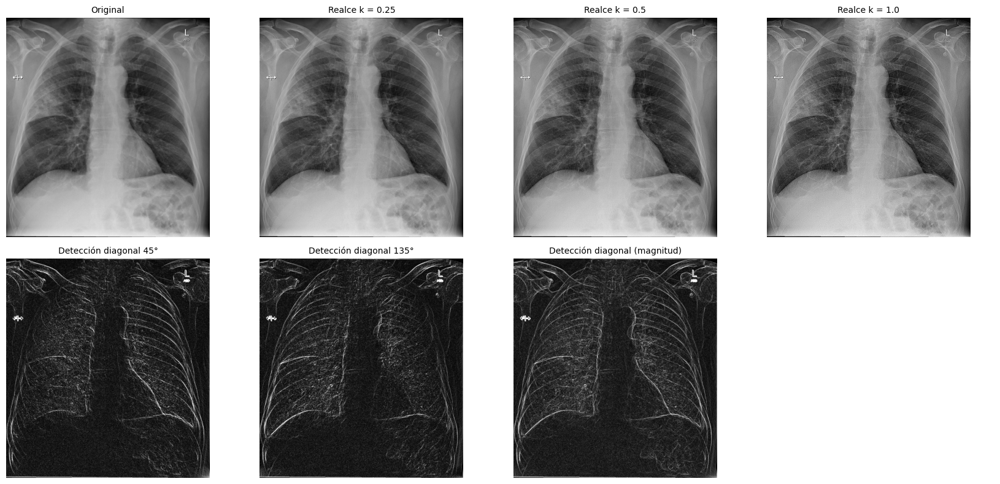

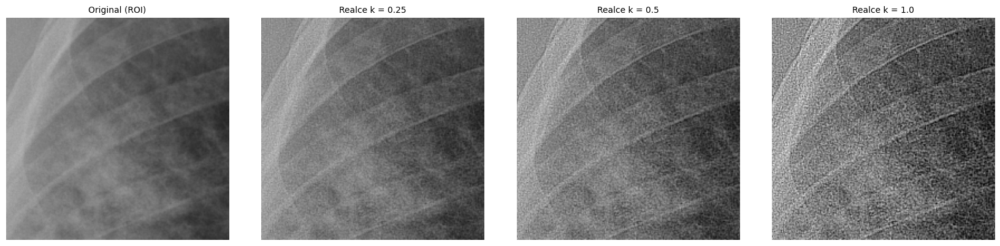

In [ ]:
def mascara_realce(k):
    """Máscara de realce: centro 1+8k, vecinos -k (suma = 1, conserva el brillo)."""
    m = -k * np.ones((3, 3), np.float32)
    m[1, 1] = 1 + 8 * k
    return m

for k in (0.25, 0.5, 1.0):
    print(f"k = {k}\n", mascara_realce(k), "\n")

realces = {k: cv2.filter2D(rx, -1, mascara_realce(k)) for k in (0.25, 0.5, 1.0)}

diag_45 = np.array([[ 0,  1, 2],
                    [-1,  0, 1],
                    [-2, -1, 0]], np.float32)
diag_135 = np.array([[2,  1,  0],
                     [1,  0, -1],
                     [0, -1, -2]], np.float32)
d45 = aplicar(rx, diag_45)
d135 = aplicar(rx, diag_135)
diag_mag = np.sqrt(d45 ** 2 + d135 ** 2)

mostrar([rx, realces[0.25], realces[0.5], realces[1.0],
         a_uint8(d45), a_uint8(d135), a_uint8(diag_mag)],
        ["Original", "Realce k = 0.25", "Realce k = 0.5", "Realce k = 1.0",
         "Detección diagonal 45°", "Detección diagonal 135°", "Detección diagonal (magnitud)"],
        2, 4, tam=(4.2, 4))

# Acercamiento al ROI para comparar el realce
mostrar([rx[y0:y1, x0:x1]] + [realces[k][y0:y1, x0:x1] for k in (0.25, 0.5, 1.0)],
        ["Original (ROI)", "Realce k = 0.25", "Realce k = 0.5", "Realce k = 1.0"],
        1, 4, tam=(4.2, 4))

## 1.5 Comparación final de los resultados

Se coloca en una sola figura el mismo acercamiento (ROI) con el original y los filtros más representativos (todos con kernel de 5×5 donde aplica), para compararlos lado a lado.

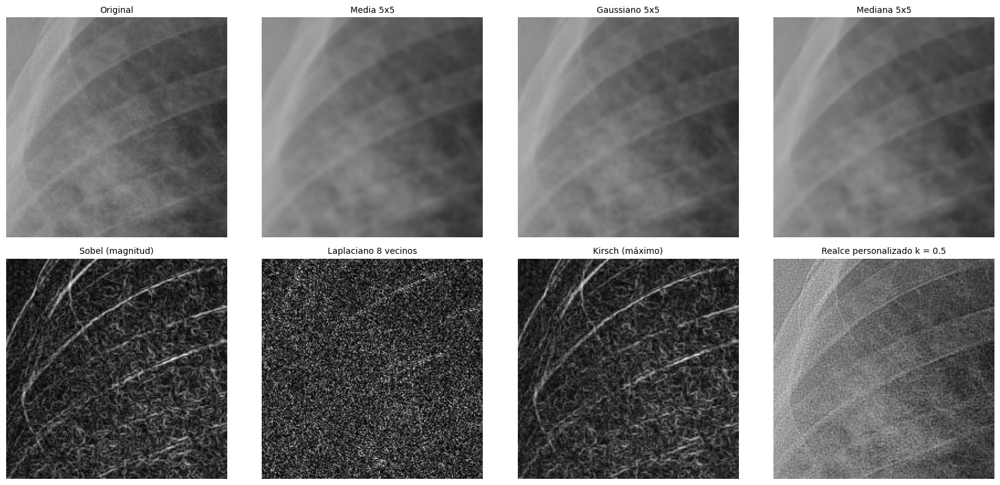

In [ ]:
comparacion = [
    (rx, "Original"),
    (filtro_media(rx, 5), "Media 5x5"),
    (filtro_gauss(rx, 5), "Gaussiano 5x5"),
    (filtro_mediana(rx, 5), "Mediana 5x5"),
    (a_uint8(sobel_mag), "Sobel (magnitud)"),
    (a_uint8(lap8), "Laplaciano 8 vecinos"),
    (a_uint8(kirsch_max), "Kirsch (máximo)"),
    (realces[0.5], "Realce personalizado k = 0.5"),
]
mostrar([im[y0:y1, x0:x1] for im, _ in comparacion], [t for _, t in comparacion],
        2, 4, tam=(4.2, 4))

# PARTE II · Filtros en el dominio de la frecuencia

## 2.1 Carga de dos imágenes médicas diferentes

* **Imagen A:** retinografía (fotografía de fondo de ojo), convertida a escala de grises y redimensionada a 512×512 px.
* **Imagen B:** corte axial de tomografía computarizada (TC) de pulmón. Se borra la letra "D" de la esquina para que no afecte al espectro.

Ambas se guardan como arreglos `float32` listos para la Transformada de Fourier.

Retinografía (512, 512) uint8
TC de pulmón (343, 508) uint8


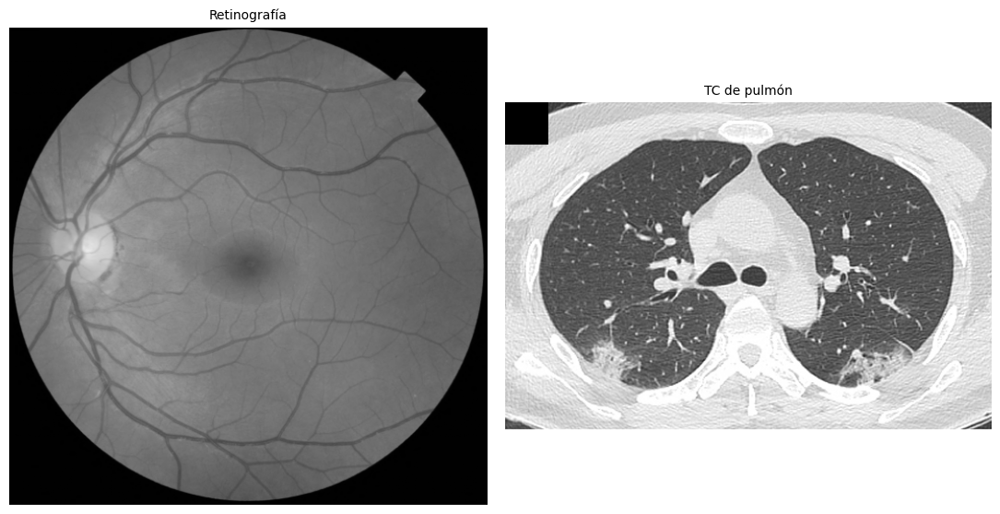

In [ ]:
# Imagen A: retinografía
retina_rgb = skdata.retina()
retina = cv2.cvtColor(retina_rgb, cv2.COLOR_RGB2GRAY)
retina = cv2.resize(retina, (512, 512), interpolation=cv2.INTER_AREA)

# Imagen B: TC de pulmón
descargar(URL_TC, "tc_pulmonar.jpg")
tc = cv2.imread("tc_pulmonar.jpg", cv2.IMREAD_GRAYSCALE)
tc[:45, :45] = 0                      # se elimina la etiqueta "D" de la figura original

imagenes = {"Retinografía": retina, "TC de pulmón": tc}
for nombre, im in imagenes.items():
    print(nombre, im.shape, im.dtype)

mostrar(list(imagenes.values()), list(imagenes.keys()), 1, 2, tam=(5.5, 5.5))

## 2.2 Transformada de Fourier y espectro de magnitud

Se calcula la FFT en 2D con `np.fft.fft2` y se desplaza con `np.fft.fftshift` para que las **bajas frecuencias queden en el centro**. Para poder visualizarlo se usa la escala logarítmica `log(1 + |F|)`, porque la magnitud del componente central es enorme comparada con el resto.

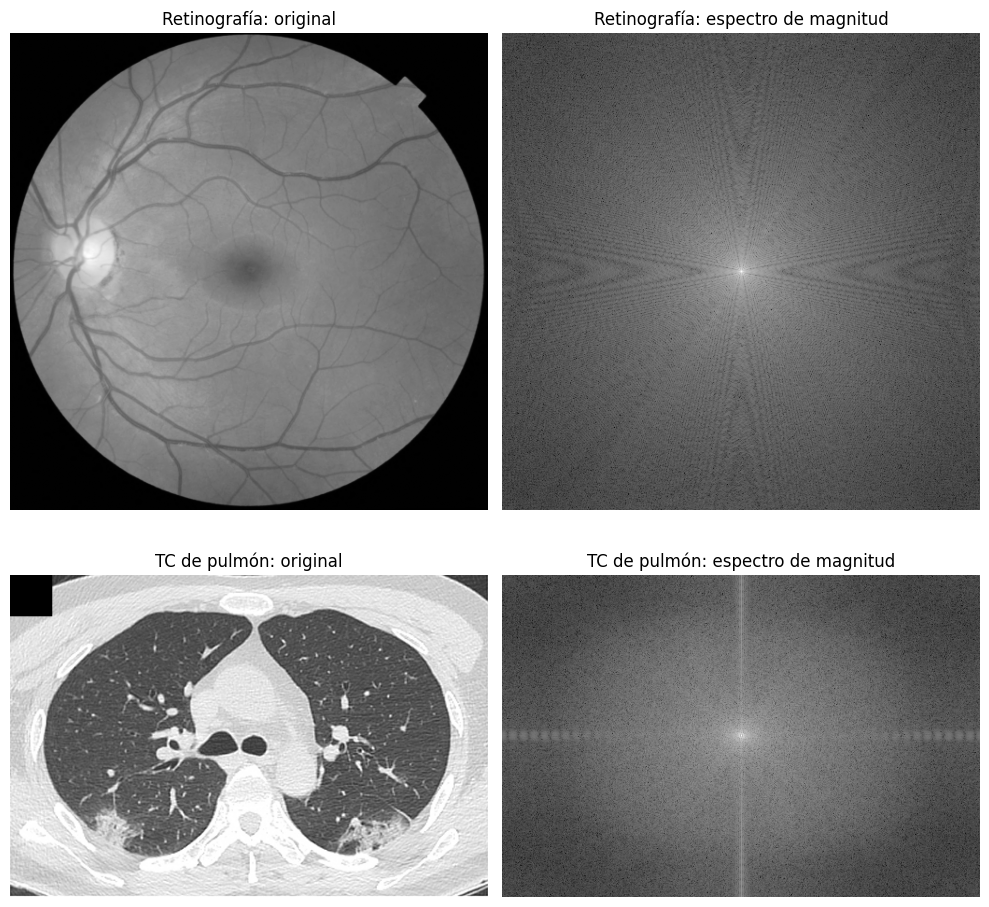

In [ ]:
def fft_centrada(img):
    """FFT 2D con las bajas frecuencias desplazadas al centro."""
    return np.fft.fftshift(np.fft.fft2(img.astype(np.float32)))

def espectro(F):
    """Espectro de magnitud en escala logarítmica (para visualizar)."""
    return np.log1p(np.abs(F))

espectros = {nombre: fft_centrada(im) for nombre, im in imagenes.items()}

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for fila, (nombre, im) in enumerate(imagenes.items()):
    axs[fila, 0].imshow(im, cmap="gray"); axs[fila, 0].set_title(f"{nombre}: original")
    axs[fila, 1].imshow(espectro(espectros[nombre]), cmap="gray"); axs[fila, 1].set_title(f"{nombre}: espectro de magnitud")
    axs[fila, 0].axis("off"); axs[fila, 1].axis("off")
plt.tight_layout(); plt.show()

## 2.3 Construcción de las máscaras de frecuencia

Cada máscara es una matriz del mismo tamaño que el espectro, con valores entre 0 (se elimina esa frecuencia) y 1 (se conserva). Se calcula la distancia `D` de cada punto al centro y a partir de ella:

**Pasa bajas** (dejan pasar solo lo cercano al centro):
* **Ideal circular:** vale 1 si `D ≤ r` y 0 en caso contrario.
* **Gaussiano:** `exp(-D² / 2r²)`, transición suave sin cortes bruscos.

**Pasa altas** (eliminan lo cercano al centro):
* **Círculo:** vale 0 dentro del radio `r` y 1 fuera de él.
* **Anillo:** deja pasar solo las frecuencias entre dos radios `r1` y `r2` (elimina las más bajas y las más altas).
* **Cruz:** elimina las frecuencias bajas ubicadas sobre los ejes horizontal y vertical (una cruz centrada) y conserva el resto.

In [ ]:
def distancia_centro(forma):
    """Matriz con la distancia de cada punto al centro del espectro."""
    filas, cols = forma
    y, x = np.ogrid[:filas, :cols]
    return np.sqrt((y - filas // 2) ** 2 + (x - cols // 2) ** 2)

# ---------- Pasa bajas ----------
def pasa_bajas_ideal(forma, r):
    return (distancia_centro(forma) <= r).astype(np.float32)

def pasa_bajas_gauss(forma, r):
    return np.exp(-(distancia_centro(forma) ** 2) / (2 * r ** 2)).astype(np.float32)

# ---------- Pasa altas ----------
def pasa_altas_circulo(forma, r):
    return (distancia_centro(forma) > r).astype(np.float32)

def pasa_altas_anillo(forma, r1, r2):
    D = distancia_centro(forma)
    return ((D >= r1) & (D <= r2)).astype(np.float32)

def pasa_altas_cruz(forma, largo, ancho):
    """Elimina una cruz centrada (brazos de medio-largo `largo` y medio-ancho `ancho`)."""
    filas, cols = forma
    y, x = np.ogrid[:filas, :cols]
    dy, dx = np.abs(y - filas // 2), np.abs(x - cols // 2)
    brazo_horizontal = (dy <= ancho) & (dx <= largo)
    brazo_vertical = (dx <= ancho) & (dy <= largo)
    return (~(brazo_horizontal | brazo_vertical)).astype(np.float32)

## 2.4 Aplicación del filtro y medición de su efecto

`aplicar_mascara` multiplica el espectro por la máscara y regresa al dominio espacial con la transformada inversa (`ifftshift` + `ifft2`). Para cuantificar cuánta información se pierde con cada configuración se calcula:

* **Energía conservada (%):** porcentaje de la energía del espectro (|F|²) que sobrevive a la máscara.
* **PSNR (dB):** parecido con la imagen original (solo tiene sentido en los pasa bajas; en los pasa altas se elimina el nivel de gris medio, por lo que no se compara).
* **Detalle relativo:** desviación estándar del Laplaciano de la imagen filtrada entre la de la original; mide cuánta nitidez (bordes y textura) se conserva. Un valor de 1 equivale a la nitidez original.

In [ ]:
def aplicar_mascara(F, M):
    """Multiplica el espectro por la máscara y regresa al dominio espacial."""
    G = F * M
    resultado = np.real(np.fft.ifft2(np.fft.ifftshift(G)))
    return G, resultado

def visible(resultado, tipo):
    """Pasa bajas: recorta a 0-255. Pasa altas: reescala (el resultado trae valores negativos)."""
    if tipo == "PB":
        return np.clip(resultado, 0, 255).astype(np.uint8)
    return a_uint8(resultado)

def metricas(img, F, M, resultado, tipo):
    energia = 100 * np.sum(np.abs(F * M) ** 2) / np.sum(np.abs(F) ** 2)
    detalle = cv2.Laplacian(resultado.astype(np.float32), cv2.CV_32F).std() / \
              cv2.Laplacian(img.astype(np.float32), cv2.CV_32F).std()
    psnr = cv2.PSNR(img, np.clip(resultado, 0, 255).astype(np.uint8)) if tipo == "PB" else np.nan
    return float(energia), float(psnr), float(detalle)

def probar_filtros(nombre_img, lista, titulo):
    """Muestra para cada filtro: máscara, espectro filtrado e imagen reconstruida. Devuelve la tabla de métricas."""
    img, F = imagenes[nombre_img], espectros[nombre_img]
    fig, axs = plt.subplots(len(lista), 3, figsize=(12, 4 * len(lista)))
    axs = np.atleast_2d(axs)
    filas = []
    for i, (etiqueta, M, tipo) in enumerate(lista):
        G, res = aplicar_mascara(F, M)
        axs[i, 0].imshow(M, cmap="gray");                     axs[i, 0].set_title(f"Máscara: {etiqueta}")
        axs[i, 1].imshow(espectro(G), cmap="gray");           axs[i, 1].set_title("Espectro filtrado")
        axs[i, 2].imshow(visible(res, tipo), cmap="gray");    axs[i, 2].set_title("Imagen reconstruida (IFFT)")
        for ax in axs[i]:
            ax.axis("off")
        e, p, d = metricas(img, F, M, res, tipo)
        filas.append({"Filtro": etiqueta, "Energía conservada (%)": e, "PSNR (dB)": p, "Detalle relativo": d})
    fig.suptitle(f"{nombre_img} – {titulo}", fontsize=14)
    plt.tight_layout(); plt.show()
    return pd.DataFrame(filas)

## 2.5 Filtros pasa bajas con diferentes radios de corte

Para cada imagen se aplican el **pasa bajas ideal** y el **pasa bajas gaussiano** con radios de **20, 50 y 80 píxeles**. A menor radio se conserva menos del espectro y la imagen se ve más borrosa; el filtro ideal, además, puede producir ondulaciones alrededor de los bordes (efecto de anillado o *ringing*).

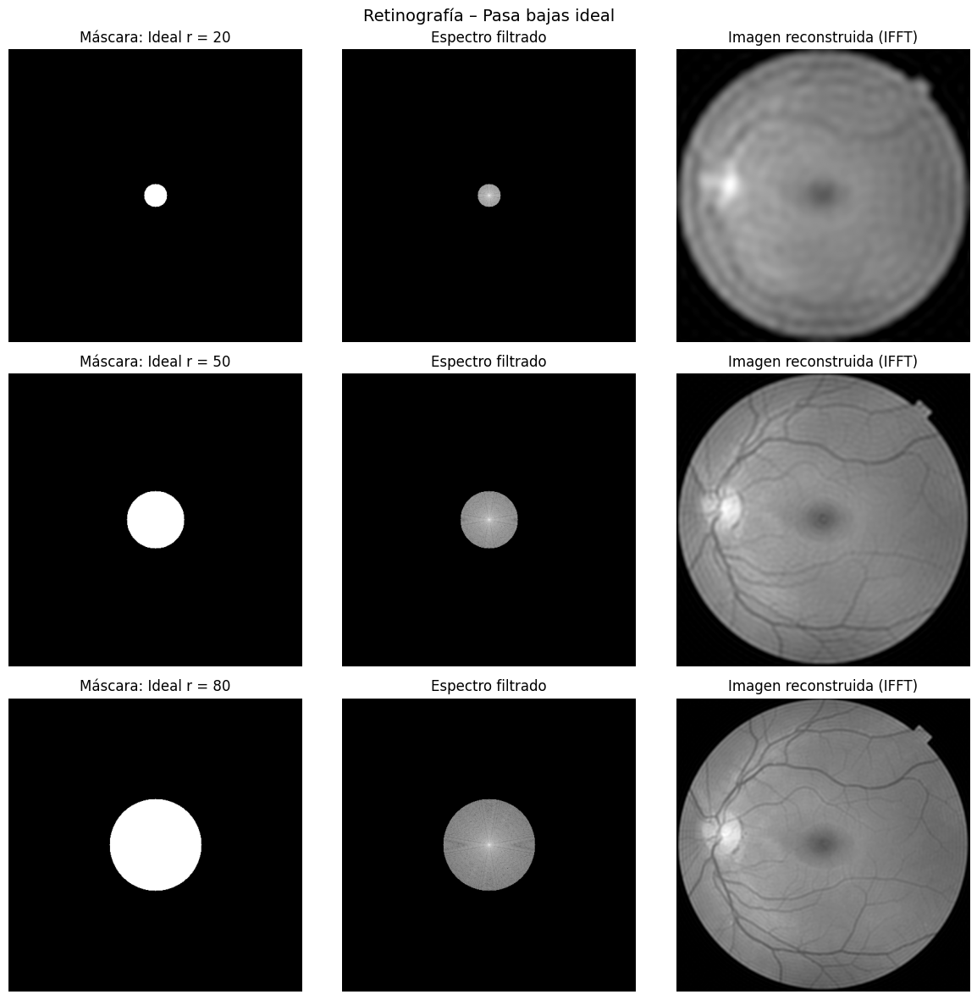

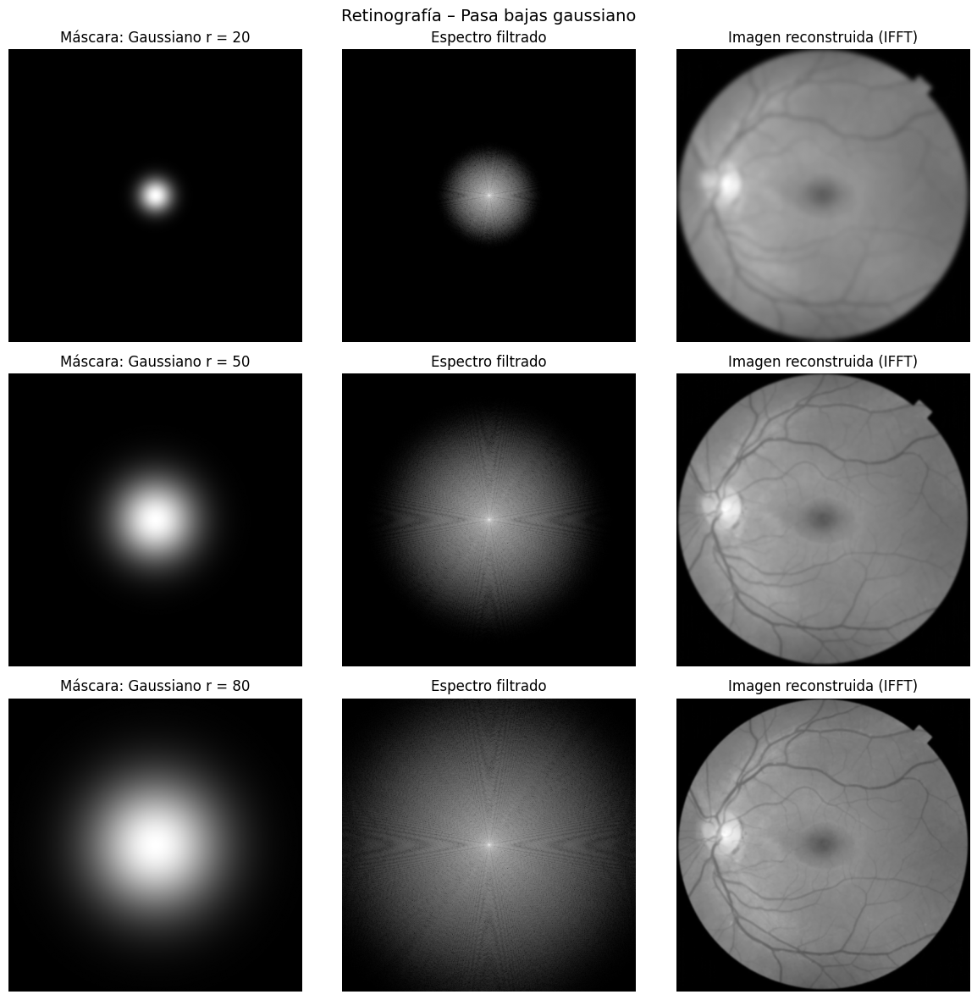

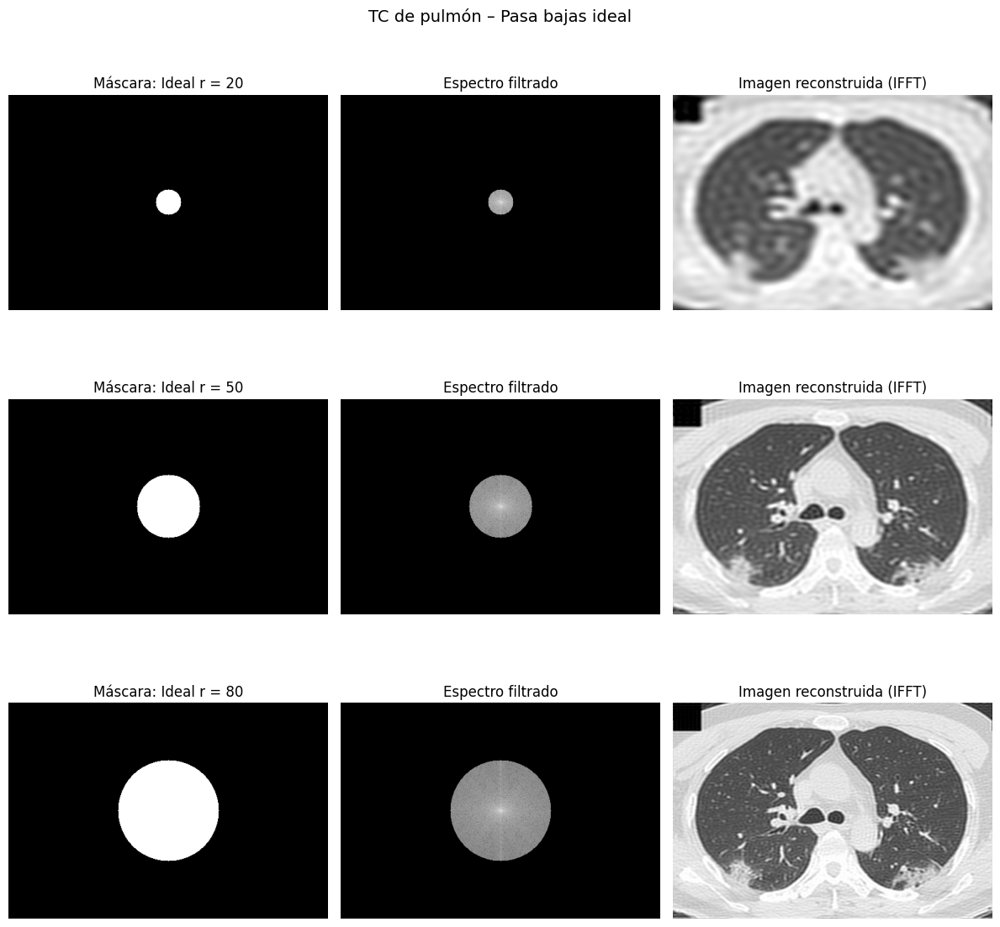

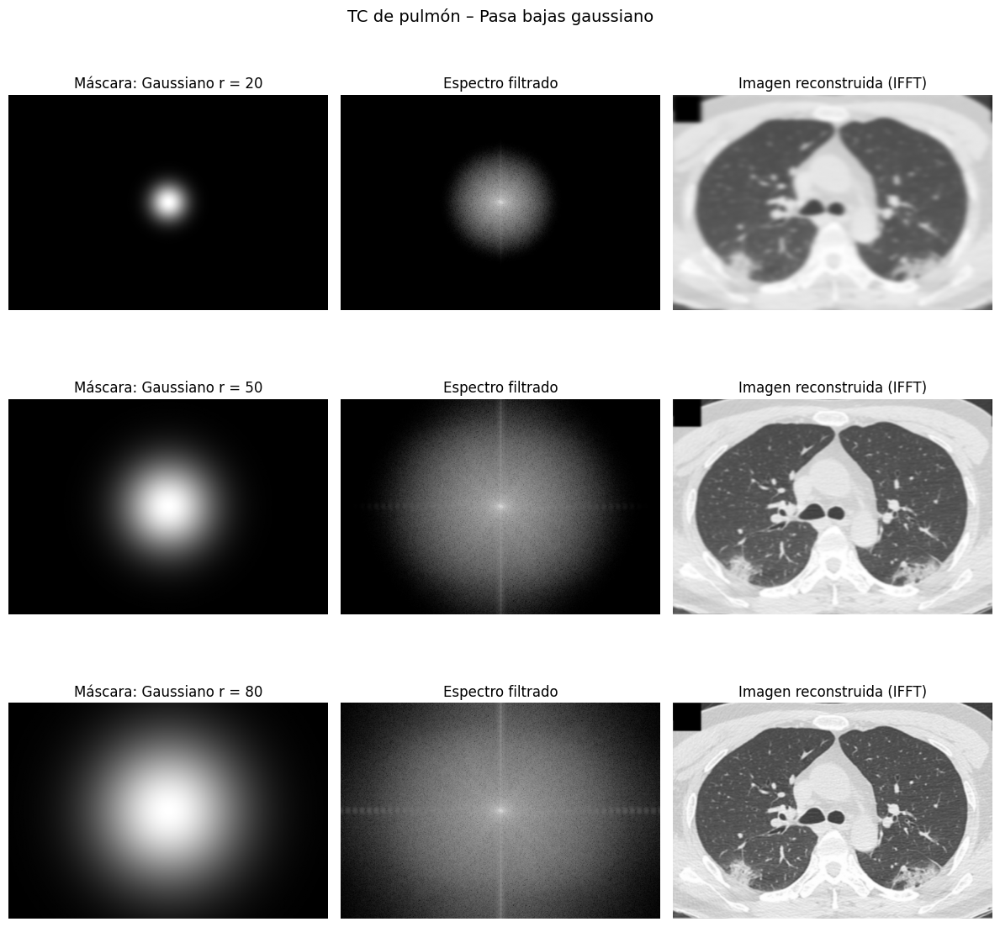


Retinografía · pasa bajas ideal
      Filtro  Energía conservada (%)  PSNR (dB)  Detalle relativo
Ideal r = 20                   99.12      28.48              0.05
Ideal r = 50                   99.74      33.78              0.19
Ideal r = 80                   99.89      37.57              0.34

Retinografía · pasa bajas gauss
          Filtro  Energía conservada (%)  PSNR (dB)  Detalle relativo
Gaussiano r = 20                   98.51      29.97              0.06
Gaussiano r = 50                   99.45      35.68              0.19
Gaussiano r = 80                   99.70      39.51              0.34

TC de pulmón · pasa bajas ideal
      Filtro  Energía conservada (%)  PSNR (dB)  Detalle relativo
Ideal r = 20                   98.37      20.86              0.06
Ideal r = 50                   99.21      24.03              0.20
Ideal r = 80                   99.59      26.91              0.42

TC de pulmón · pasa bajas gauss
          Filtro  Energía conservada (%)  PSNR (dB)  Detalle

In [ ]:
radios = [20, 50, 80]
tablas = {}

for nombre in imagenes:
    forma = imagenes[nombre].shape
    ideal = [(f"Ideal r = {r}", pasa_bajas_ideal(forma, r), "PB") for r in radios]
    gauss = [(f"Gaussiano r = {r}", pasa_bajas_gauss(forma, r), "PB") for r in radios]
    tablas[(nombre, "ideal")] = probar_filtros(nombre, ideal, "Pasa bajas ideal")
    tablas[(nombre, "gauss")] = probar_filtros(nombre, gauss, "Pasa bajas gaussiano")

for (nombre, tipo), t in tablas.items():
    print(f"\n{nombre} · pasa bajas {tipo}")
    print(t.round(2).to_string(index=False))

## 2.6 Filtros pasa altas con diferentes configuraciones

Se prueban tres configuraciones: **círculo** (radios 10 y 30), **anillo** (entre 30 y 100 px) y **cruz** (brazos de medio-largo 60 px y medio-ancho 10 px). Como estos filtros eliminan el componente central (el brillo promedio), la imagen reconstruida se reescala a 0–255 para poder verla; lo que se observa son principalmente los bordes y detalles finos.

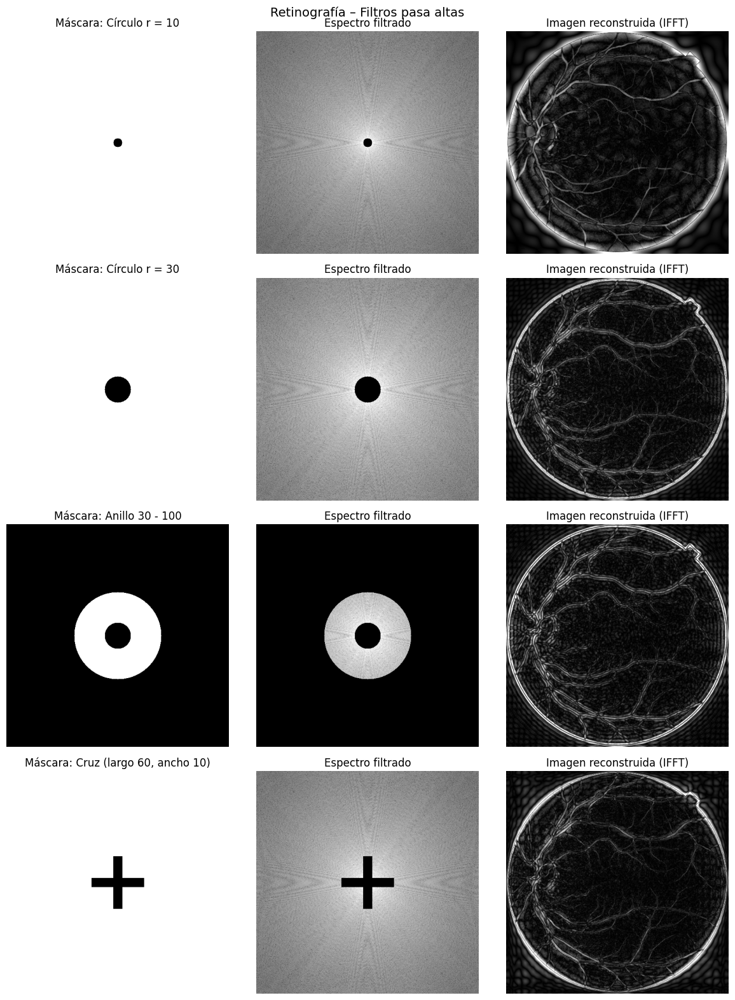

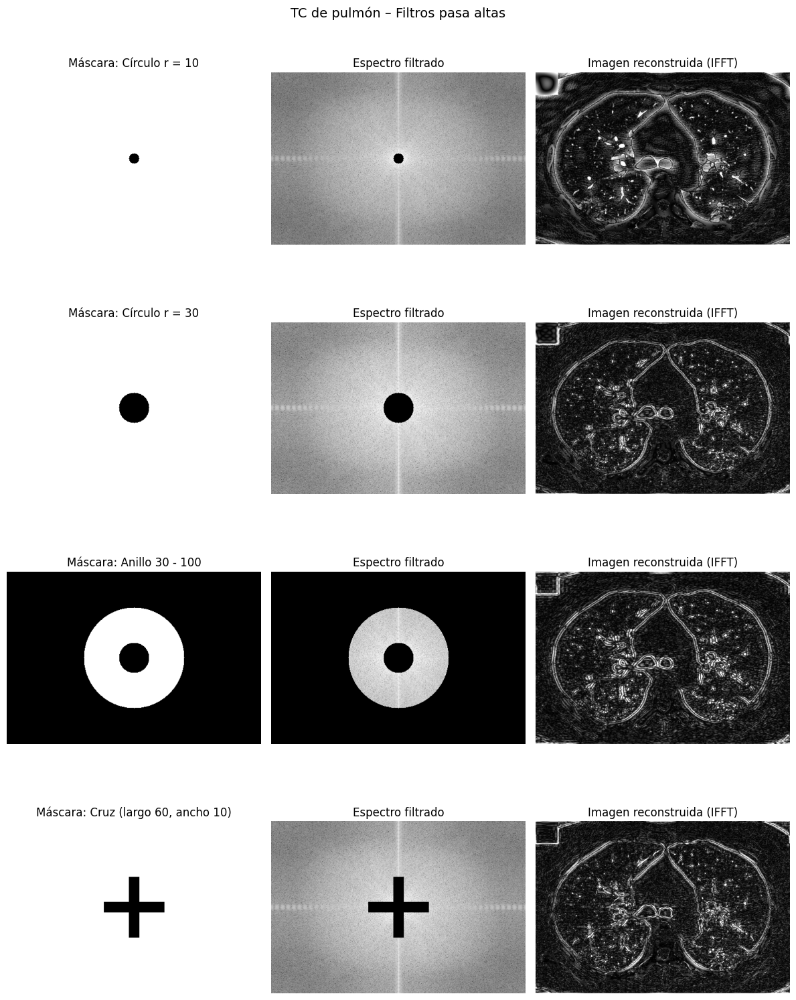


Retinografía · pasa altas
                   Filtro  Energía conservada (%)  PSNR (dB)  Detalle relativo
           Círculo r = 10                    1.75        NaN              1.00
           Círculo r = 30                    0.54        NaN              1.00
          Anillo 30 - 100                    0.48        NaN              0.44
Cruz (largo 60, ancho 10)                    0.61        NaN              0.99

TC de pulmón · pasa altas
                   Filtro  Energía conservada (%)  PSNR (dB)  Detalle relativo
           Círculo r = 10                    2.69        NaN              1.00
           Círculo r = 30                    1.23        NaN              1.01
          Anillo 30 - 100                    0.99        NaN              0.59
Cruz (largo 60, ancho 10)                    1.21        NaN              1.01


In [ ]:
tablas_pa = {}
for nombre in imagenes:
    forma = imagenes[nombre].shape
    altas = [("Círculo r = 10", pasa_altas_circulo(forma, 10), "PA"),
             ("Círculo r = 30", pasa_altas_circulo(forma, 30), "PA"),
             ("Anillo 30 - 100", pasa_altas_anillo(forma, 30, 100), "PA"),
             ("Cruz (largo 60, ancho 10)", pasa_altas_cruz(forma, 60, 10), "PA")]
    tablas_pa[nombre] = probar_filtros(nombre, altas, "Filtros pasa altas")

for nombre, t in tablas_pa.items():
    print(f"\n{nombre} · pasa altas")
    print(t.round(2).to_string(index=False))

## 2.7 Comparación final en el dominio de la frecuencia

En una sola figura se coloca, para cada imagen, el original junto con los resultados más representativos: pasa bajas con radio 20 y 80, pasa altas en círculo, anillo y cruz.

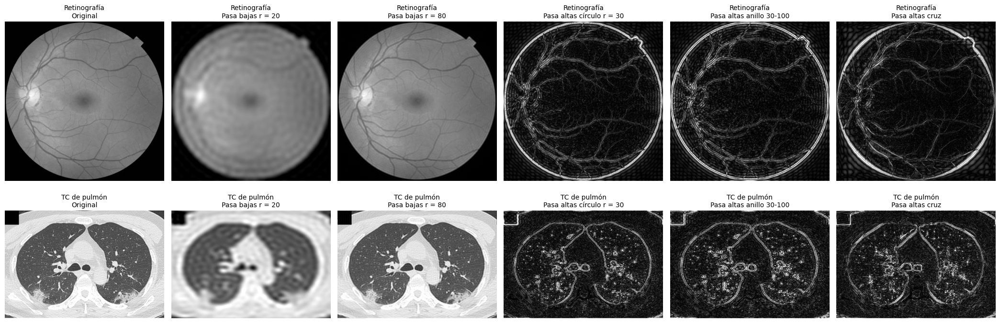

In [ ]:
fig, axs = plt.subplots(2, 6, figsize=(21, 7.5))
for fila, nombre in enumerate(imagenes):
    img, F, forma = imagenes[nombre], espectros[nombre], imagenes[nombre].shape
    casos = [("Original", None, None),
             ("Pasa bajas r = 20", pasa_bajas_ideal(forma, 20), "PB"),
             ("Pasa bajas r = 80", pasa_bajas_ideal(forma, 80), "PB"),
             ("Pasa altas círculo r = 30", pasa_altas_circulo(forma, 30), "PA"),
             ("Pasa altas anillo 30-100", pasa_altas_anillo(forma, 30, 100), "PA"),
             ("Pasa altas cruz", pasa_altas_cruz(forma, 60, 10), "PA")]
    for col, (titulo, M, tipo) in enumerate(casos):
        salida = img if M is None else visible(aplicar_mascara(F, M)[1], tipo)
        axs[fila, col].imshow(salida, cmap="gray")
        axs[fila, col].set_title(f"{nombre}\n{titulo}", fontsize=10)
        axs[fila, col].axis("off")
plt.tight_layout(); plt.show()